In [1]:
"""RFM segmentation: PCA + K-Means + DBSCAN + t-SNE."""
import sys, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

K, SEED = 4, 42   # final k (check elbow/silhouette plot first)


In [2]:
# 1. Load + clean (works for the UCI .xlsx/.csv too)
import os, urllib.request, zipfile
path = next((a for a in sys.argv[1:] if a.endswith((".csv", ".xlsx"))), "Online Retail.xlsx")
if not os.path.exists(path):
    urllib.request.urlretrieve("https://archive.ics.uci.edu/static/public/352/online+retail.zip", "r.zip")
    zipfile.ZipFile("r.zip").extractall()
df = pd.read_excel(path) if path.endswith("xlsx") else pd.read_csv(path, encoding="ISO-8859-1")
df = df.rename(columns={"Invoice": "InvoiceNo", "Price": "UnitPrice", "Customer ID": "CustomerID"})
df = df.dropna(subset=["CustomerID"])
df = df[~df.InvoiceNo.astype(str).str.startswith("C") & (df.Quantity > 0) & (df.UnitPrice > 0)]
df["Total"] = df.Quantity * df.UnitPrice
df["InvoiceDate"] = pd.to_datetime(df.InvoiceDate)


In [3]:
# 2. RFM table
snap = df.InvoiceDate.max() + pd.Timedelta(days=1)
rfm = df.groupby("CustomerID").agg(Recency=("InvoiceDate", lambda x: (snap - x.max()).days),
                                   Frequency=("InvoiceNo", "nunique"), Monetary=("Total", "sum"))
print(rfm.describe().round(1))

# 3. Log + scale
X = StandardScaler().fit_transform(np.log1p(rfm))

# 4. PCA
pca = PCA(n_components=2, random_state=SEED); Xp = pca.fit_transform(X)
print("PCA variance ratio:", pca.explained_variance_ratio_.round(3))


       Recency  Frequency  Monetary
count   4338.0     4338.0    4338.0
mean      92.5        4.3    2054.3
std      100.0        7.7    8989.2
min        1.0        1.0       3.8
25%       18.0        1.0     307.4
50%       51.0        2.0     674.5
75%      142.0        5.0    1661.7
max      374.0      209.0  280206.0
PCA variance ratio: [0.751 0.188]


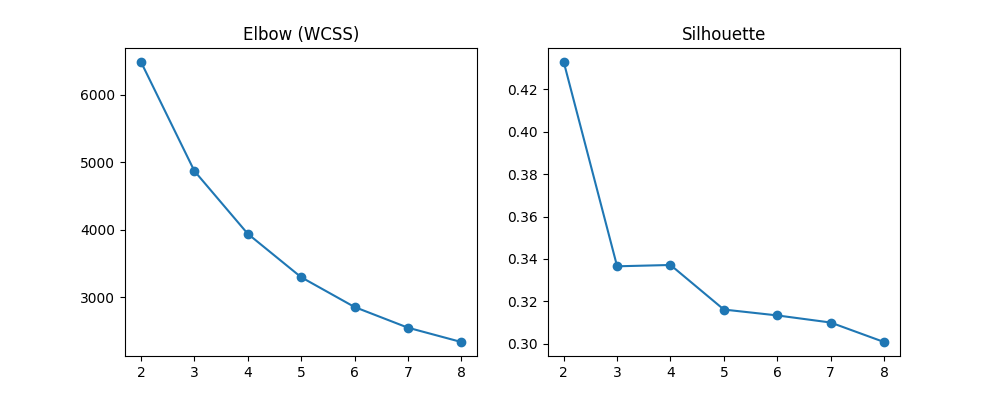

In [8]:
# 5. K-Means: elbow + silhouette
ks = range(2, 9)
km_s = [KMeans(k, n_init=10, random_state=SEED).fit(X) for k in ks]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(ks, [m.inertia_ for m in km_s], "o-"); ax[0].set_title("Elbow (WCSS)")
ax[1].plot(ks, [silhouette_score(X, m.labels_) for m in km_s], "o-"); ax[1].set_title("Silhouette")
plt.savefig("fig1_elbow_silhouette.png"); plt.close()
rfm["KMeans"] = KMeans(K, n_init=10, random_state=SEED).fit_predict(X)
from IPython.display import Image
Image("fig1_elbow_silhouette.png")



DBSCAN eps=0.40: clusters=3, noise=118


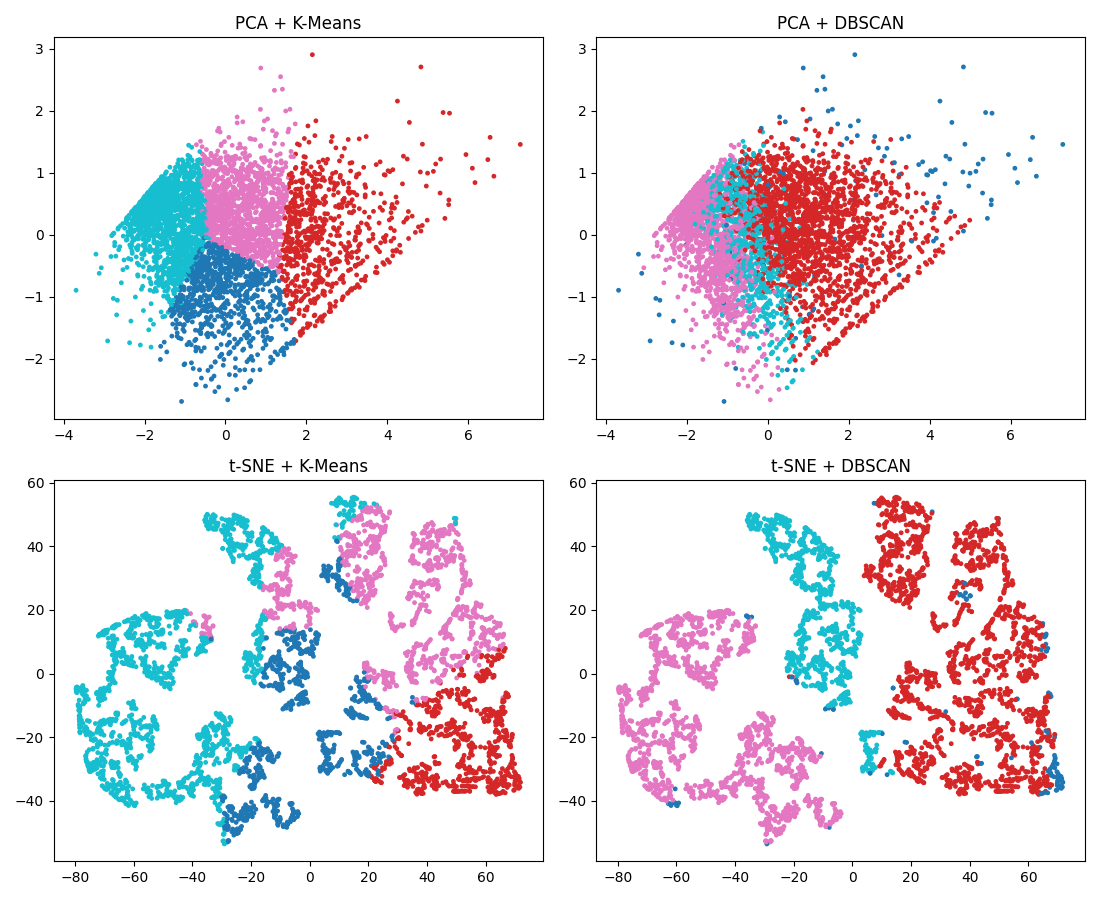

In [9]:
# 6. DBSCAN (eps from k-distance graph, 95th percentile heuristic)
ms = 6
kd = np.sort(NearestNeighbors(n_neighbors=ms).fit(X).kneighbors(X)[0][:, -1])
eps = np.percentile(kd, 95)
rfm["DBSCAN"] = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
print(f"DBSCAN eps={eps:.2f}: clusters={rfm.DBSCAN.nunique() - (-1 in rfm.DBSCAN.values)}, noise={(rfm.DBSCAN == -1).sum()}")

# 7. Visualize PCA and t-SNE
Xt = TSNE(perplexity=30, init="pca", learning_rate="auto", random_state=SEED).fit_transform(X)
fig, ax = plt.subplots(2, 2, figsize=(11, 9))
for a, e, c, t in [(ax[0,0], Xp, "KMeans", "PCA + K-Means"), (ax[0,1], Xp, "DBSCAN", "PCA + DBSCAN"),
                   (ax[1,0], Xt, "KMeans", "t-SNE + K-Means"), (ax[1,1], Xt, "DBSCAN", "t-SNE + DBSCAN")]:
    a.scatter(e[:, 0], e[:, 1], c=rfm[c], cmap="tab10", s=6); a.set_title(t)
plt.tight_layout(); plt.savefig("fig2_pca_tsne.png"); plt.close()
Image("fig2_pca_tsne.png")


In [6]:
# 8. Profile clusters -> personas
prof = rfm.groupby("KMeans").agg(Customers=("Recency", "size"), Recency=("Recency", "mean"),
        Frequency=("Frequency", "mean"), Monetary=("Monetary", "mean"), Revenue=("Monetary", "sum")).round(1)
prof["%Revenue"] = (prof.Revenue / prof.Revenue.sum() * 100).round(1)
med, q75 = rfm[["Recency", "Frequency", "Monetary"]].median(), rfm[["Recency", "Frequency", "Monetary"]].quantile(.75)
q90 = rfm[["Frequency", "Monetary"]].quantile(.90)
def persona(r):
    rec, fr, mo = r.Recency <= med.Recency, r.Frequency >= med.Frequency, r.Monetary >= med.Monetary
    if rec and r.Frequency >= q90.Frequency and r.Monetary >= q90.Monetary: return "Champions"
    if rec and fr and mo: return "Loyal Customers"
    if fr and mo: return "At-Risk High Value"
    if rec: return "New / Promising"
    if r.Recency >= q75.Recency and not fr: return "Lost / Hibernating"
    return "Need Attention"
action = {"Champions": "VIP perks, early access, referral rewards", "Loyal Customers": "Upsell/cross-sell, loyalty points",
          "At-Risk High Value": "Personal win-back offer, feedback survey", "New / Promising": "Welcome series, 2nd-purchase coupon",
          "Need Attention": "Limited-time offers, reminders", "Lost / Hibernating": "Cheap reactivation or suppress"}
prof["Persona"] = prof.apply(persona, axis=1); prof["Action"] = prof.Persona.map(action)
print(prof.to_string())
rfm.assign(Persona=rfm.KMeans.map(prof.Persona)).to_csv("rfm_with_segments.csv")

        Customers  Recency  Frequency  Monetary    Revenue  %Revenue             Persona                                     Action
KMeans                                                                                                                             
0             837     18.1        2.1     551.8   461873.0       5.2     New / Promising        Welcome series, 2nd-purchase coupon
1             716     12.1       13.7    8074.3  5781175.1      64.9           Champions  VIP perks, early access, referral rewards
2            1173     71.1        4.1    1802.8  2114718.4      23.7  At-Risk High Value   Personal win-back offer, feedback survey
3            1612    182.5        1.3     343.5   553641.5       6.2  Lost / Hibernating             Cheap reactivation or suppress
